<a href="https://colab.research.google.com/github/Rich-10-afk/SemProject_MLEngine/blob/main/RandomForest_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Offscroll - Screen Time Activity Recommender
## ICS 3202 Semester Project - ML Engine

**Project:** Offscroll is a mobile app that helps users reduce screen time by recommending offline activities (walking, puzzles, reading, stretching, podcasts) when they exceed their usage limits.

**Objective:** Train a model that can predict which activity to recommend based on the user's phone usage patterns.

**Dataset:** Mobile Phone Use Logs - usage data from 342 people over about 4 weeks each. Includes screen events, app usage, and timing patterns.

**Approach:** Supervised classification using Random Forest

**Features used are limited to what the app can actually collect:**
- Screen unlock/on events (from UsageStatsManager + AccessibilityService)
- App usage and switching patterns (from usage monitoring)
- Time of day and day of week (from session timestamps)
- Age and gender (optional, collected during setup)

## Data Understanding & EDA

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# load user summary data
# The dataset should be placed in a folder called 'mpud/mobile_phone_use/' relative to this notebook
# with pinfo.csv and a 'data/' subfolder containing 342 per-user CSV files
DATA_DIR = os.path.join(os.path.dirname(os.path.abspath('__file__')), 'mpud', 'mobile_phone_use')

pinfo = pd.read_csv(f'{DATA_DIR}/pinfo.csv')
print(f'{pinfo.shape[0]} users, {pinfo.shape[1]} columns')
pinfo.head()

342 users, 32 columns


,uuid,sdk,device,locale,timezone,start_date,last_active,age,gender,Big5Agreeableness,...,esm_response_rate,esm_passed,esm_passed_rate,bored_frac,valence_mean,tense_calm_mean,tired_awake_mean,valence_sd,tense_calm_sd,tired_awake_sd
0,u072142,17,TCT-ONE TOUCH 4033X,es_ES,1,2016-06-19 17:42:16,2016-07-12 11:10:41,53,1,22.0,...,13.07,40,100.0,0.000,1.000,-0.975,0.600,0.000,0.156,0.572
1,u0cba7d,19,bq-Aquaris E5 FHD,es_ES,1,2016-06-19 19:02:52,2016-07-11 22:58:25,54,0,23.0,...,19.94,68,100.0,0.018,0.794,-0.273,0.106,0.472,0.770,0.837
2,u11abb4,19,LGE-LG-D320,es_ES,1,2016-06-09 18:01:52,2016-07-12 08:53:30,28,0,16.0,...,30.53,149,100.0,0.031,0.655,-0.547,0.248,0.578,0.729,0.818
3,u11cef8,16,LGE-LG-E430,es_ES,1,2016-06-13 12:06:27,2016-07-11 22:17:18,40,1,20.0,...,16.58,65,100.0,0.003,0.738,-0.877,0.585,0.505,0.372,0.579
4,u11cf22,23,samsung-SM-G920F,es_ES,1,2016-06-09 15:41:41,2016-07-11 22:54:25,38,1,19.0,...,46.80,198,100.0,0.000,0.028,0.035,-0.785,0.175,0.222,0.290


In [ ]:
pinfo.info()

<class 'pandas.DataFrame'>
RangeIndex: 342 entries, 0 to 341
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   uuid                   342 non-null    str    
 1   sdk                    342 non-null    int64  
 2   device                 342 non-null    str    
 3   locale                 342 non-null    str    
 4   timezone               342 non-null    int64  
 5   start_date             342 non-null    str    
 6   last_active            342 non-null    str    
 7   age                    342 non-null    int64  
 8   gender                 342 non-null    int64  
 9   Big5Agreeableness      167 non-null    float64
 10  Big5Conscientiousness  167 non-null    float64
 11  Big5Extraversion       167 non-null    float64
 12  Big5Openness           167 non-null    float64
 13  Big5Neuroticism        167 non-null    float64
 14  BPSScore               93 non-null     float64
 15  BPSExternal      

In [ ]:
pinfo.describe()

,sdk,timezone,age,gender,Big5Agreeableness,Big5Conscientiousness,Big5Extraversion,Big5Openness,Big5Neuroticism,BPSScore,...,esm_response_rate,esm_passed,esm_passed_rate,bored_frac,valence_mean,tense_calm_mean,tired_awake_mean,valence_sd,tense_calm_sd,tired_awake_sd
count,342.000000,342.000000,342.000000,342.000000,167.000000,167.000000,167.000000,167.000000,167.000000,93.000000,...,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000
mean,20.058480,0.982456,37.915205,0.529240,18.101796,14.814371,11.748503,15.580838,11.467066,27.505376,...,30.247105,96.912281,99.201608,0.033553,0.673064,-0.532591,0.234254,0.370424,0.468336,0.589348
std,2.291659,0.241542,11.027896,0.499876,4.012983,5.112732,4.986389,4.561929,4.742508,8.657271,...,13.167727,48.495166,4.555132,0.059136,0.337102,0.360157,0.400062,0.204966,0.197324,0.185971
min,15.000000,-3.000000,18.000000,0.000000,4.000000,0.000000,0.000000,0.000000,1.000000,3.000000,...,4.950000,21.000000,33.650000,0.000000,-1.000000,-1.000000,-1.000000,0.000000,0.000000,0.000000
25%,19.000000,1.000000,30.000000,0.000000,16.000000,12.000000,8.000000,12.000000,8.000000,23.000000,...,20.907500,67.000000,100.000000,0.003000,0.512750,-0.826000,-0.037500,0.226000,0.349000,0.471000
50%,21.000000,1.000000,38.000000,1.000000,18.000000,15.000000,12.000000,16.000000,12.000000,27.000000,...,28.070000,89.000000,100.000000,0.013500,0.795000,-0.608500,0.274000,0.376500,0.468000,0.593000
75%,22.000000,1.000000,46.000000,1.000000,21.000000,19.000000,15.000000,19.000000,15.000000,34.000000,...,38.390000,120.750000,100.000000,0.038000,0.926250,-0.312000,0.529500,0.518250,0.598500,0.715000
max,23.000000,2.000000,66.000000,1.000000,24.000000,24.000000,24.000000,24.000000,24.000000,49.000000,...,93.230000,338.000000,100.000000,0.710000,1.000000,1.000000,0.987000,0.860000,1.000000,0.999000


### Aggregating sensor data from individual user files

Each user has their own CSV with thousands of rows (one per sensor event). We extract only features that map to what the Offscroll app can actually track - screen events, app switching, and time-of-day patterns.

In [ ]:
def aggregate_user_sensors(filepath):
    """Pull out features from one user's sensor data that match what our app tracks."""
    try:
        df = pd.read_csv(filepath, low_memory=False)
    except Exception:
        return None

    user_id = df['uuid'].iloc[0]

    # screen unlocks and on events (app tracks these via UsageMonitorService)
    screen = df[df['sensor_id'] == 'Screen']
    unlocks = screen[screen['Screen_Value'] == 'Unlocked'].shape[0]
    screen_ons = screen[screen['Screen_Value'] == 'On'].shape[0]

    # peak usage hour (app derives this from session timestamps)
    hour_counts = df['HourOfDay'].value_counts()
    peak_hour = hour_counts.idxmax() if len(hour_counts) > 0 else 12

    # evening and weekend usage ratios (from timestamps)
    total_events = len(df)
    evening_events = df[df['HourOfDay'].between(18, 23)].shape[0]
    evening_ratio = evening_events / total_events if total_events > 0 else 0

    weekend_events = df[df['DayOfWeek'].isin([5, 6])].shape[0]
    weekend_ratio = weekend_events / total_events if total_events > 0 else 0

    # app switching (app tracks foreground app changes)
    apps = df[df['sensor_id'] == 'App']
    app_switches = apps.shape[0]
    unique_apps = apps['App_Value'].nunique()

    return {
        'uuid': user_id,
        'screen_unlocks': unlocks,
        'screen_ons': screen_ons,
        'peak_hour': peak_hour,
        'evening_ratio': evening_ratio,
        'weekend_ratio': weekend_ratio,
        'app_switches': app_switches,
        'unique_apps': unique_apps,
    }

In [ ]:
# process all 342 user files
sensor_dir = f'{DATA_DIR}/data'
user_files = [f for f in os.listdir(sensor_dir) if f.endswith('.csv')]

print(f'Processing {len(user_files)} user files...')
sensor_features = []
for i, fname in enumerate(user_files):
    result = aggregate_user_sensors(os.path.join(sensor_dir, fname))
    if result:
        sensor_features.append(result)
    if (i + 1) % 50 == 0:
        print(f'  {i + 1}/{len(user_files)} done')

sensor_df = pd.DataFrame(sensor_features)
print(f'\nResult: {sensor_df.shape}')
sensor_df.head()

Processing 342 user files...


  50/342 done


  100/342 done


  150/342 done


  200/342 done


  250/342 done


  300/342 done



Result: (342, 8)


,uuid,screen_unlocks,screen_ons,peak_hour,evening_ratio,weekend_ratio,app_switches,unique_apps
0,u34fea5,515,824,18,0.504773,0.267762,4773,36
1,u96286f,539,986,13,0.282842,0.220202,4690,115
2,u56a637,755,1247,12,0.260109,0.265326,3146,41
3,u344af2,1408,0,21,0.299602,0.350835,4879,57
4,u31ae1c,463,684,23,0.318736,0.162642,3049,48


In [ ]:
# merge the two datasets on user id
merged = pinfo.merge(sensor_df, on='uuid', how='inner')
print(f'Merged: {merged.shape}')
merged.head()

Merged: (342, 39)


,uuid,sdk,device,locale,timezone,start_date,last_active,age,gender,Big5Agreeableness,...,valence_sd,tense_calm_sd,tired_awake_sd,screen_unlocks,screen_ons,peak_hour,evening_ratio,weekend_ratio,app_switches,unique_apps
0,u072142,17,TCT-ONE TOUCH 4033X,es_ES,1,2016-06-19 17:42:16,2016-07-12 11:10:41,53,1,22.0,...,0.000,0.156,0.572,498,524,1,0.284418,0.284108,1533,25
1,u0cba7d,19,bq-Aquaris E5 FHD,es_ES,1,2016-06-19 19:02:52,2016-07-11 22:58:25,54,0,23.0,...,0.472,0.770,0.837,1383,0,13,0.269009,0.267108,2573,35
2,u11abb4,19,LGE-LG-D320,es_ES,1,2016-06-09 18:01:52,2016-07-12 08:53:30,28,0,16.0,...,0.578,0.729,0.818,1931,3124,21,0.342292,0.310575,8012,39
3,u11cef8,16,LGE-LG-E430,es_ES,1,2016-06-13 12:06:27,2016-07-11 22:17:18,40,1,20.0,...,0.505,0.372,0.579,432,929,12,0.292899,0.271763,58,6
4,u11cf22,23,samsung-SM-G920F,es_ES,1,2016-06-09 15:41:41,2016-07-11 22:54:25,38,1,19.0,...,0.175,0.222,0.290,1992,3802,18,0.367166,0.307785,9581,44


### EDA - Key Observations

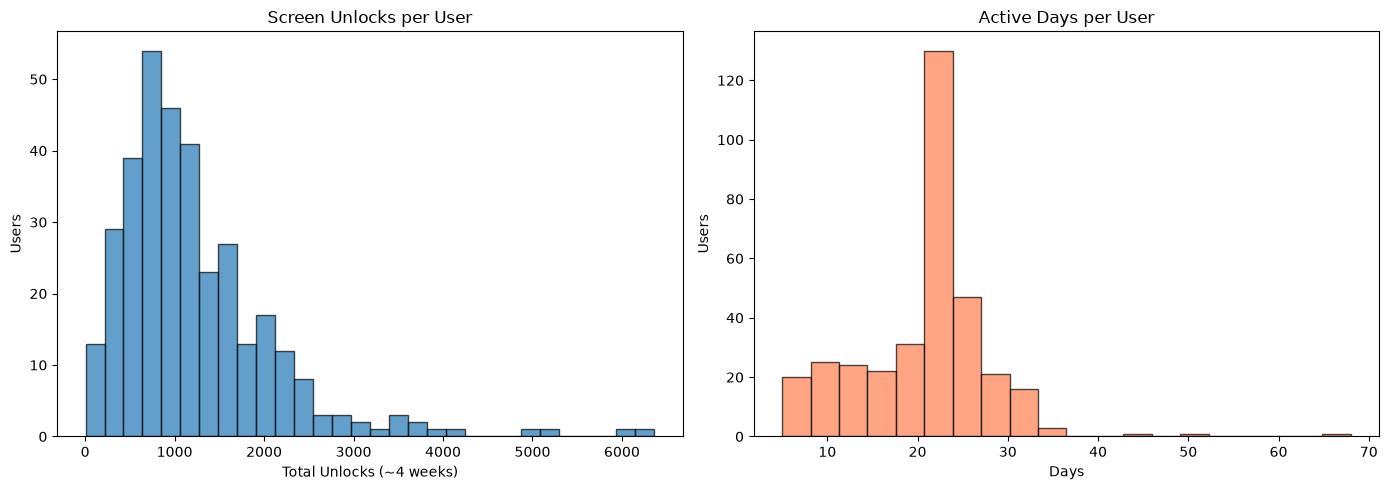

Unlocks range from 5 to 6360
Mean: 1221, Median: 1028
There's a big spread here - some users barely touch their phone while others unlock hundreds of times a day


In [ ]:
# Observation 1: how often do users unlock their phones?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(merged['screen_unlocks'], bins=30, edgecolor='black', alpha=0.7)
axes[0].set_title('Screen Unlocks per User')
axes[0].set_xlabel('Total Unlocks (~4 weeks)')
axes[0].set_ylabel('Users')

axes[1].hist(merged['active_days'], bins=20, edgecolor='black', alpha=0.7, color='coral')
axes[1].set_title('Active Days per User')
axes[1].set_xlabel('Days')
axes[1].set_ylabel('Users')

plt.tight_layout()
plt.show()

print(f"Unlocks range from {merged['screen_unlocks'].min()} to {merged['screen_unlocks'].max()}")
print(f"Mean: {merged['screen_unlocks'].mean():.0f}, Median: {merged['screen_unlocks'].median():.0f}")
print("There's a big spread here - some users barely touch their phone while others unlock hundreds of times a day")

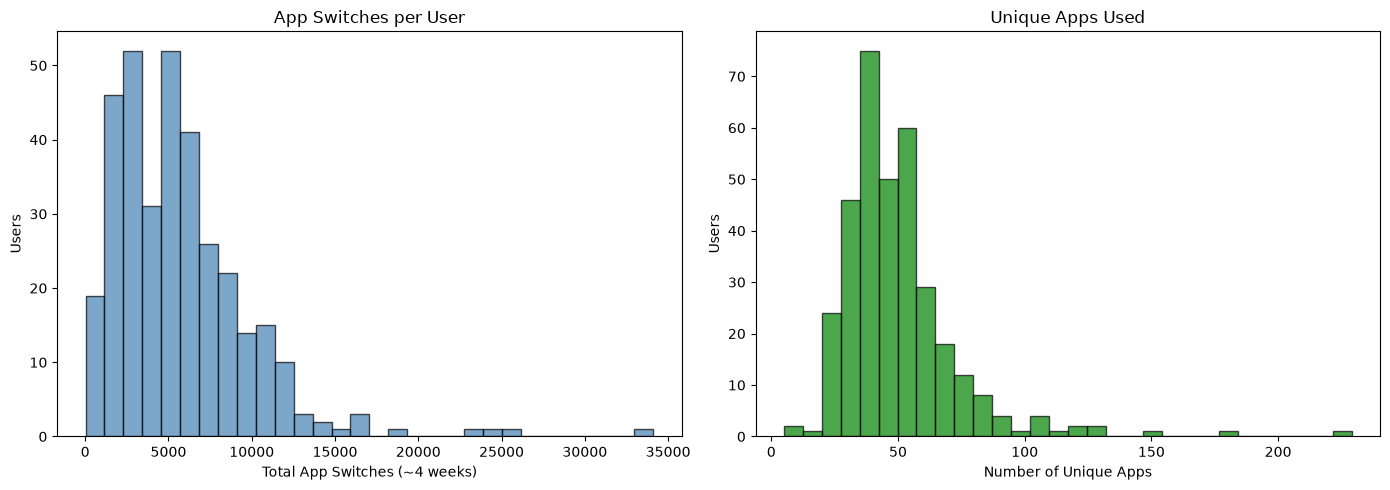

App switches range from 21 to 34104
Users switch between 50 apps on average
Heavy app switchers tend to be restless - good candidates for puzzle tasks


In [ ]:
# Observation 2: how many apps do users switch between?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(merged['app_switches'], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].set_title('App Switches per User')
axes[0].set_xlabel('Total App Switches (~4 weeks)')
axes[0].set_ylabel('Users')

axes[1].hist(merged['unique_apps'], bins=30, edgecolor='black', alpha=0.7, color='green')
axes[1].set_title('Unique Apps Used')
axes[1].set_xlabel('Number of Unique Apps')
axes[1].set_ylabel('Users')

plt.tight_layout()
plt.show()

print(f"App switches range from {merged['app_switches'].min()} to {merged['app_switches'].max()}")
print(f"Users switch between {merged['unique_apps'].mean():.0f} apps on average")
print("Heavy app switchers tend to be restless - good candidates for puzzle tasks")

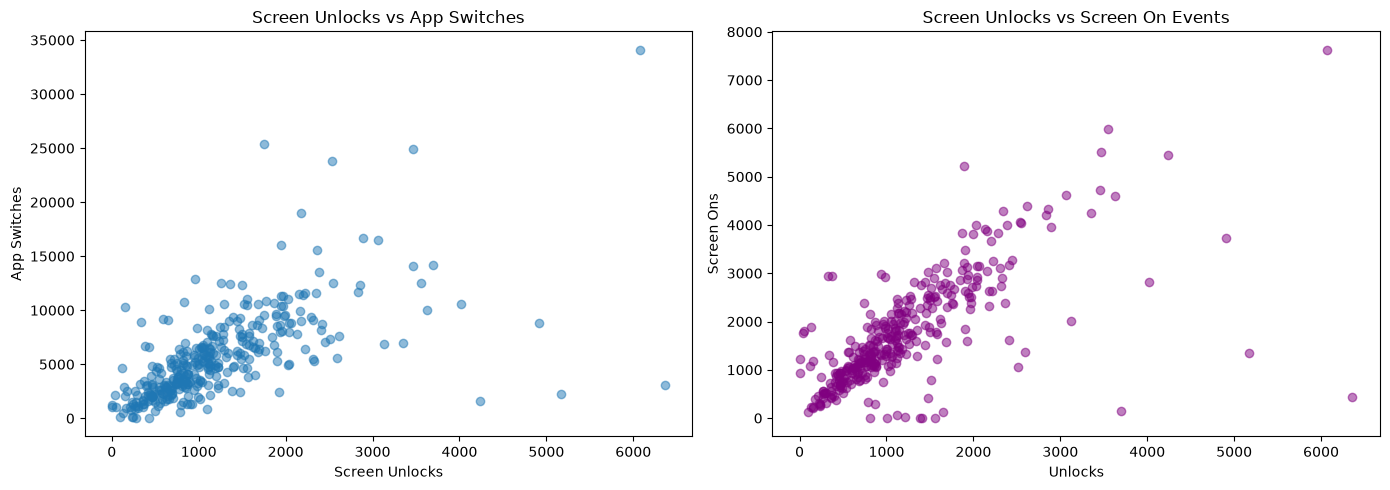

Unlock-switch correlation: 0.635
Unlock-screen on correlation: 0.697
Strong positive correlations - heavy unlockers also switch apps more and have more screen on events


In [ ]:
# Observation 3: relationship between screen unlocks and app switching
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(merged['screen_unlocks'], merged['app_switches'], alpha=0.5)
axes[0].set_title('Screen Unlocks vs App Switches')
axes[0].set_xlabel('Screen Unlocks')
axes[0].set_ylabel('App Switches')

axes[1].scatter(merged['screen_unlocks'], merged['screen_ons'], alpha=0.5, color='purple')
axes[1].set_title('Screen Unlocks vs Screen On Events')
axes[1].set_xlabel('Unlocks')
axes[1].set_ylabel('Screen Ons')

plt.tight_layout()
plt.show()

print(f"Unlock-switch correlation: {merged['screen_unlocks'].corr(merged['app_switches']):.3f}")
print(f"Unlock-screen on correlation: {merged['screen_unlocks'].corr(merged['screen_ons']):.3f}")
print("Strong positive correlations - heavy unlockers also switch apps more and have more screen on events")

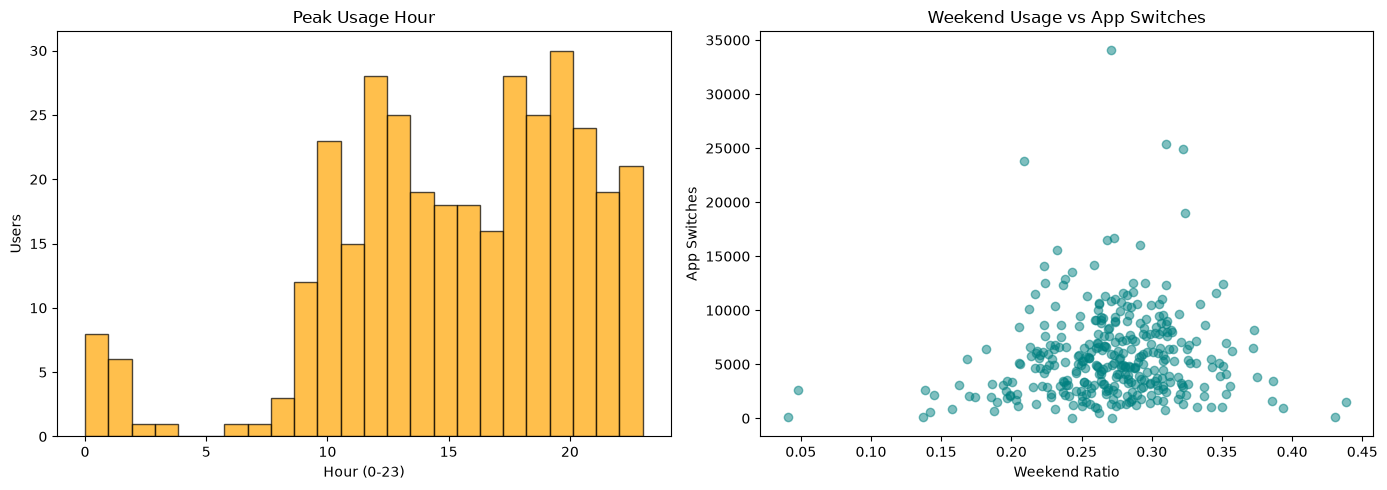

Most common peak hour: 20
Weekend ratio: 0.271 (would be ~0.286 if usage was even)
Peak usage is in the evening hours - this affects what activities make sense to recommend


In [ ]:
# Observation 4: when do people use their phones the most?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(merged['peak_hour'], bins=24, edgecolor='black', alpha=0.7, color='orange')
axes[0].set_title('Peak Usage Hour')
axes[0].set_xlabel('Hour (0-23)')
axes[0].set_ylabel('Users')

axes[1].scatter(merged['weekend_ratio'], merged['app_switches'], alpha=0.5, color='teal')
axes[1].set_title('Weekend Usage vs App Switches')
axes[1].set_xlabel('Weekend Ratio')
axes[1].set_ylabel('App Switches')

plt.tight_layout()
plt.show()

print(f"Most common peak hour: {merged['peak_hour'].mode().iloc[0]}")
print(f"Weekend ratio: {merged['weekend_ratio'].mean():.3f} (would be ~0.286 if usage was even)")
print("Peak usage is in the evening hours - this affects what activities make sense to recommend")

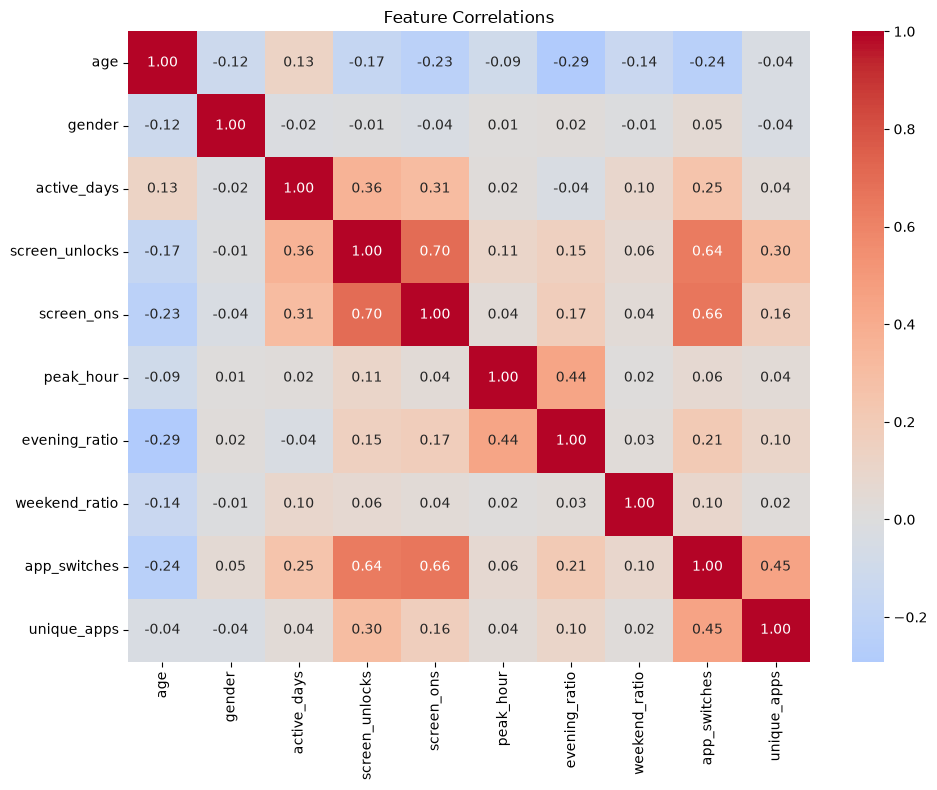

In [ ]:
# correlation heatmap of features we're actually using
corr_cols = ['age', 'gender', 'active_days', 'screen_unlocks', 'screen_ons',
             'peak_hour', 'evening_ratio', 'weekend_ratio', 'app_switches', 'unique_apps']

plt.figure(figsize=(10, 8))
sns.heatmap(merged[corr_cols].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Feature Correlations')
plt.tight_layout()
plt.show()

## Data Cleaning

In [ ]:
# Start with the merged dataset
df = merged.copy()
print(f'Starting shape: {df.shape}')

Starting shape: (342, 39)


In [ ]:
# Step 1: Check for duplicates
dup_count = df.duplicated().sum()
print(f'Duplicate rows: {dup_count}')
if dup_count > 0:
    df = df.drop_duplicates()
    print(f'After removing duplicates: {df.shape}')

Duplicate rows: 0


In [ ]:
# Step 2: drop columns the app can't track
# keeping: age, gender (optional user input), active_days, screen/app/timing features
# dropping: device info, personality tests, mental health scores, mood/emotional state,
# study-specific columns, and activity sensors (app only has step counter during walk tasks)

drop_cols = [
    'uuid', 'sdk', 'device', 'locale', 'timezone', 'start_date', 'last_active',
    # personality & mental health - not collected
    'Big5Agreeableness', 'Big5Conscientiousness', 'Big5Extraversion',
    'Big5Openness', 'Big5Neuroticism',
    'BPSScore', 'BPSExternal', 'BPSInternal', 'PHQ8',
    # mood/emotional state - app can't reliably track this
    'bored_frac', 'valence_mean', 'tense_calm_mean', 'tired_awake_mean',
    'valence_sd', 'tense_calm_sd', 'tired_awake_sd',
    # study-specific ESM columns
    'dim', 'esm', 'esm_responded', 'esm_response_rate',
    'esm_passed', 'esm_passed_rate',
]

df = df.drop(columns=[c for c in drop_cols if c in df.columns])
print(f'After dropping: {df.shape}')
print(f'Columns kept: {list(df.columns)}')

After dropping: (342, 10)
Columns kept: ['age', 'gender', 'active_days', 'screen_unlocks', 'screen_ons', 'peak_hour', 'evening_ratio', 'weekend_ratio', 'app_switches', 'unique_apps']


In [ ]:
# Step 3: check for incorrect/impossible values
print(f"Age: {df['age'].min()} to {df['age'].max()}")
print(f"Gender: {df['gender'].unique()}")
print(f"Screen unlocks: {df['screen_unlocks'].min()} to {df['screen_unlocks'].max()}")
print(f"Peak hour: {df['peak_hour'].min()} to {df['peak_hour'].max()}")
print(f"\nBad age values: {len(df[(df['age'] < 10) | (df['age'] > 100)])}")
print(f"Bad peak hours: {len(df[(df['peak_hour'] < 0) | (df['peak_hour'] > 23)])}")

Age: 18 to 66
Gender: [1 0]
Screen unlocks: 5 to 6360
Peak hour: 0 to 23

Bad age values: 0
Bad peak hours: 0


In [ ]:
# Step 4: check data types and structural issues
print(df.dtypes)
print(f"\nGender values: {sorted(df['gender'].unique())}")
print(f"Peak hours: {sorted(df['peak_hour'].unique())}")

age                 int64
gender              int64
active_days         int64
screen_unlocks      int64
screen_ons          int64
peak_hour           int64
evening_ratio     float64
weekend_ratio     float64
app_switches        int64
unique_apps         int64
dtype: object

Gender values: [np.int64(0), np.int64(1)]
Peak hours: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


In [ ]:
# Step 5: check for missing values
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else 'No missing values')
print(f'Total missing: {df.isnull().sum().sum()}')

No missing values
Total missing: 0


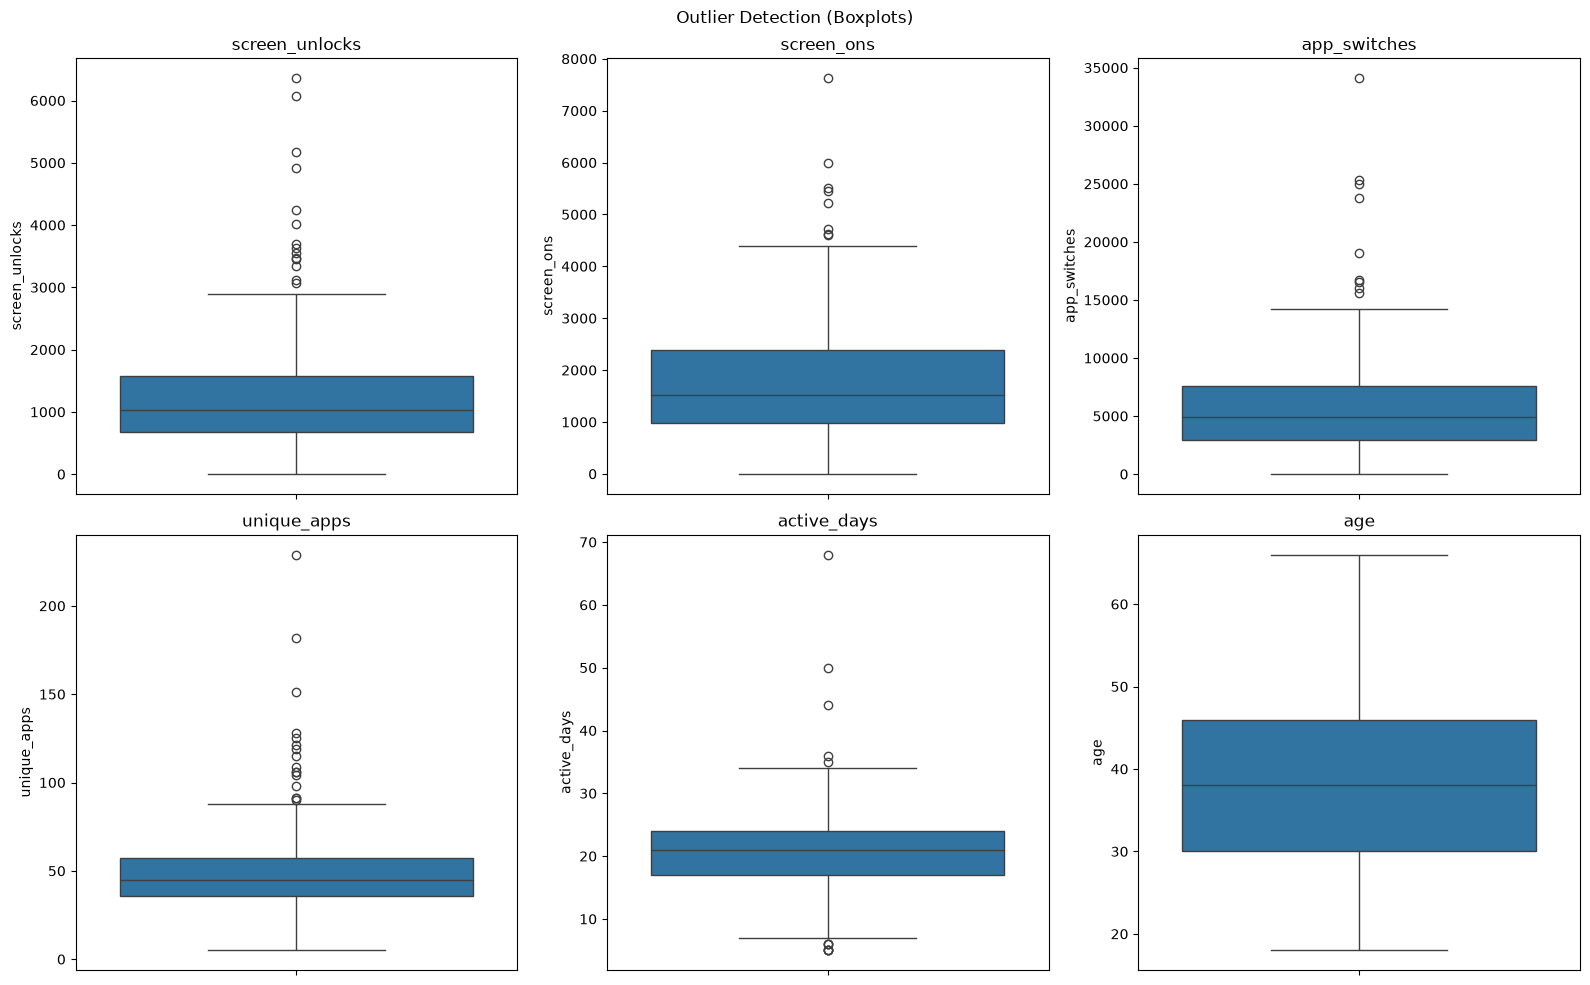

screen_unlocks: 14 outliers
screen_ons: 8 outliers
app_switches: 9 outliers
unique_apps: 16 outliers
active_days: 12 outliers
age: 0 outliers


In [ ]:
# Step 6: check for outliers using boxplots and IQR
outlier_cols = ['screen_unlocks', 'screen_ons', 'app_switches',
                'unique_apps', 'active_days', 'age']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, col in zip(axes.flatten(), outlier_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle('Outlier Detection (Boxplots)')
plt.tight_layout()
plt.show()

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)]
    print(f'{col}: {len(outliers)} outliers')

In [ ]:
# cap outliers instead of dropping (we only have 342 rows)
cap_cols = ['screen_unlocks', 'screen_ons', 'app_switches', 'unique_apps']
for col in cap_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col] = df[col].clip(lower=Q1 - 1.5*IQR, upper=Q3 + 1.5*IQR)
    print(f'Capped {col}')

Capped screen_unlocks
Capped screen_ons
Capped app_switches
Capped unique_apps


In [ ]:
# quick look at cleaned data before modelling
df.describe()

,age,gender,active_days,screen_unlocks,screen_ons,peak_hour,evening_ratio,weekend_ratio,app_switches,unique_apps
count,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.000000,342.00000,342.000000
mean,37.915205,0.529240,20.546784,1169.962719,1732.289474,15.473684,0.314878,0.271488,5512.98867,48.327485
std,11.027896,0.499876,7.253829,704.908001,1042.031794,5.345885,0.049659,0.048652,3421.22215,17.096699
min,18.000000,0.000000,5.000000,5.000000,0.000000,0.000000,0.115120,0.040858,21.00000,5.000000
25%,30.000000,0.000000,17.000000,670.250000,987.000000,12.000000,0.281719,0.247514,2898.00000,36.000000
50%,38.000000,1.000000,21.000000,1028.500000,1516.500000,16.000000,0.314534,0.273744,4935.50000,45.000000
75%,46.000000,1.000000,24.000000,1568.500000,2384.500000,20.000000,0.342067,0.301216,7593.25000,57.000000
max,66.000000,1.000000,68.000000,2915.875000,4480.750000,23.000000,0.504773,0.438072,14636.12500,88.500000


### Creating the target variable

The dataset doesn't have labels for which activity to recommend (it was collected before our app existed). We create labels using only data the app can actually track:

- **walk** - daytime users with lower app switching (less restless, good for outdoor activity)
- **puzzle** - heavy app switchers with many unique apps (restless, need mental engagement)
- **read** - evening users with fewer screen unlocks (winding down, requires internet in-app)
- **stretch** - heavy phone users with high screen unlocks and screen on events
- **podcast** - late night/weekend users with moderate usage (passive listening activity, requires internet in-app)

activity
puzzle     145
walk       125
read        52
stretch     11
podcast      9
Name: count, dtype: int64


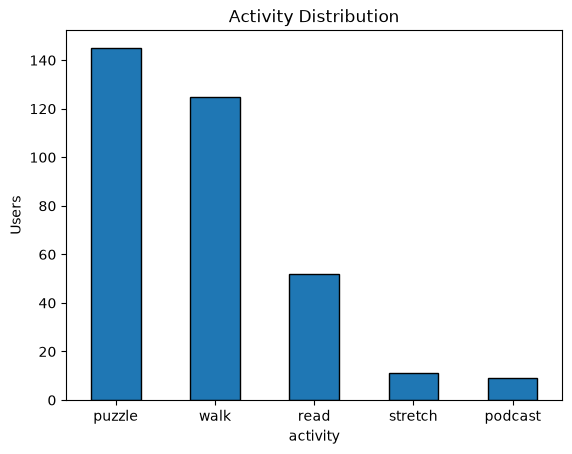

In [ ]:
def assign_activity(row):
    """Score each activity using only app-trackable data."""
    scores = {'walk': 0, 'puzzle': 0, 'read': 0, 'stretch': 0, 'podcast': 0}

    # walk: daytime user, not constantly switching apps
    if 8 <= row['peak_hour'] <= 17: scores['walk'] += 2
    if row['app_switches'] < df['app_switches'].median(): scores['walk'] += 1
    if row['weekend_ratio'] > df['weekend_ratio'].median(): scores['walk'] += 1

    # puzzle: lots of app switching and unique apps (restless behaviour)
    if row['app_switches'] > df['app_switches'].median(): scores['puzzle'] += 2
    if row['unique_apps'] > df['unique_apps'].median(): scores['puzzle'] += 1
    if row['screen_unlocks'] > df['screen_unlocks'].median(): scores['puzzle'] += 1

    # read: evening user, less frantic usage
    if row['evening_ratio'] > df['evening_ratio'].median(): scores['read'] += 2
    if 18 <= row['peak_hour'] <= 21: scores['read'] += 1
    if row['app_switches'] < df['app_switches'].median(): scores['read'] += 1

    # stretch: very heavy phone usage overall
    if row['screen_unlocks'] > df['screen_unlocks'].quantile(0.6): scores['stretch'] += 1
    if row['screen_ons'] > df['screen_ons'].quantile(0.6): scores['stretch'] += 1
    if row['active_days'] > df['active_days'].median(): scores['stretch'] += 1
    if row['evening_ratio'] < df['evening_ratio'].median(): scores['stretch'] += 1

    # podcast: late night / weekend user, moderate usage (passive listening)
    if row['peak_hour'] >= 21: scores['podcast'] += 2
    if row['weekend_ratio'] > df['weekend_ratio'].quantile(0.6): scores['podcast'] += 1
    if df['app_switches'].quantile(0.3) <= row['app_switches'] <= df['app_switches'].quantile(0.7): scores['podcast'] += 1

    return max(scores, key=scores.get)

df['activity'] = df.apply(assign_activity, axis=1)
print(df['activity'].value_counts())

df['activity'].value_counts().plot(kind='bar', edgecolor='black')
plt.title('Activity Distribution')
plt.ylabel('Users')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# set up features and target
# core = what the app automatically tracks
# optional = user provides during setup (can be skipped)

core_features = ['active_days', 'screen_unlocks', 'screen_ons',
                 'peak_hour', 'evening_ratio', 'weekend_ratio',
                 'app_switches', 'unique_apps']

optional_features = ['age', 'gender']  # collected in setup, user can skip

all_features = core_features + optional_features
X = df[all_features]
y = df['activity']

print(f'Features: {X.shape[1]} ({len(core_features)} core + {len(optional_features)} optional)')
print(f'Classes: {list(y.unique())}')

Features: 10 (8 core + 2 optional)
Classes: ['walk', 'puzzle', 'stretch', 'read', 'podcast']


In [ ]:
# scale features and encode labels
from sklearn.preprocessing import StandardScaler, LabelEncoder

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

le = LabelEncoder()
y_encoded = le.fit_transform(y)
print(f'Labels: {dict(zip(le.classes_, le.transform(le.classes_)))}')

# save cleaned (unscaled) data so partners can run the modelling section on Colab
clean_df = df[all_features].copy()
clean_df['activity'] = y.values
clean_df.to_csv('clean_data.csv', index=False)
print(f'Saved clean_data.csv ({clean_df.shape[0]} rows, {clean_df.shape[1]} columns)')

Labels: {'podcast': np.int64(0), 'puzzle': np.int64(1), 'read': np.int64(2), 'stretch': np.int64(3), 'walk': np.int64(4)}
Saved clean_data.csv (342 rows, 11 columns)


## Modelling

Using Random Forest as the base model since it handles mixed feature types well and is less prone to overfitting than a single decision tree. We validate with 5-fold cross validation since the dataset is small (342 samples).

**Google Colab:** If running on Colab without the raw dataset, start from the cell below — it loads the pre-processed `clean_data.csv` and sets up everything the modelling section needs.

In [ ]:
# --- Colab entry point ---
# If running on Colab, upload clean_data.csv to the session or mount Drive, then run from here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
import warnings
warnings.filterwarnings('ignore')

clean_df = pd.read_csv('clean_data.csv')

core_features = ['active_days', 'screen_unlocks', 'screen_ons',
                 'peak_hour', 'evening_ratio', 'weekend_ratio',
                 'app_switches', 'unique_apps']
optional_features = ['age', 'gender']
all_features = core_features + optional_features

X = clean_df[all_features]
y = clean_df['activity']

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print(f'Loaded {X_scaled.shape[0]} rows, {X_scaled.shape[1]} features')
print(f'Classes: {list(le.classes_)}')

Loaded 342 rows, 10 features
Classes: ['podcast', 'puzzle', 'read', 'stretch', 'walk']


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
print(f'Train: {X_train.shape[0]}, Test: {X_test.shape[0]}')

Train: 273, Test: 69


In [ ]:
# train random forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

     podcast       0.00      0.00      0.00         2
      puzzle       0.90      0.97      0.93        29
        read       0.83      0.91      0.87        11
     stretch       0.00      0.00      0.00         2
        walk       0.88      0.92      0.90        25

    accuracy                           0.88        69
   macro avg       0.52      0.56      0.54        69
weighted avg       0.83      0.88      0.86        69



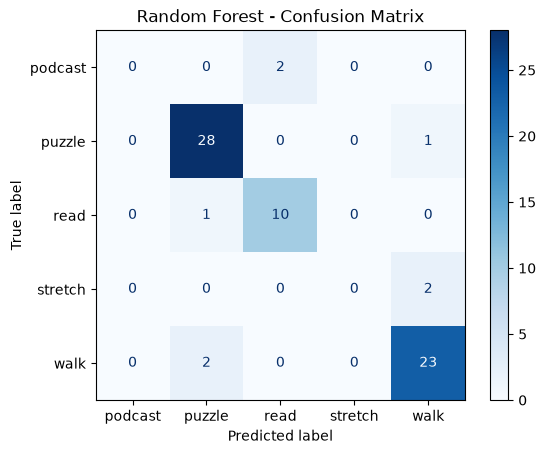

In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(cmap='Blues')
plt.title('Random Forest - Confusion Matrix')
plt.show()

In [ ]:
# 5-fold cross validation for more reliable accuracy
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf_model, X_scaled, y_encoded, cv=skf, scoring='accuracy')

for i, score in enumerate(cv_scores, 1):
    print(f'Fold {i}: {score:.4f}')
print(f'\nMean: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})')

Fold 1: 0.8986
Fold 2: 0.8841
Fold 3: 0.9118
Fold 4: 0.9265
Fold 5: 0.8088

Mean: 0.8859 (+/- 0.0410)


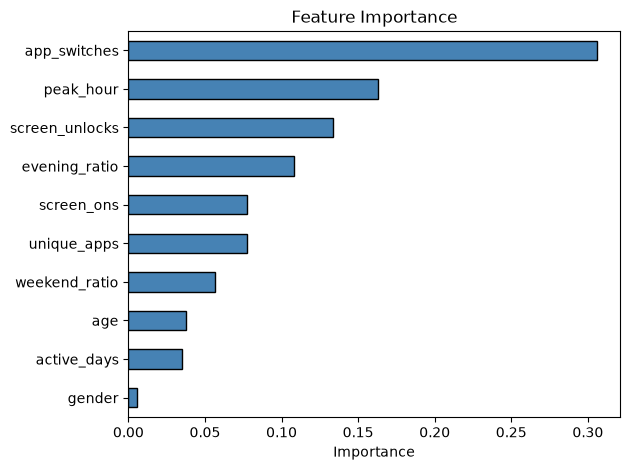

In [ ]:
# which features matter most?
importances = pd.Series(rf_model.feature_importances_, index=all_features).sort_values()
importances.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## Model Comparison

Comparing Random Forest against other classifiers to see if it's actually the best choice.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, model in models.items():
    scores = cross_val_score(model, X_scaled, y_encoded, cv=skf, scoring='accuracy')
    results[name] = scores
    print(f'{name}: {scores.mean():.4f} (+/- {scores.std():.4f})')

Random Forest: 0.8859 (+/- 0.0410)
Decision Tree: 0.8595 (+/- 0.0443)
KNN (k=5): 0.7896 (+/- 0.0501)
Logistic Regression: 0.8012 (+/- 0.0469)


In [ ]:
# bar chart comparison
names = list(results.keys())
means = [results[m].mean() for m in names]
stds = [results[m].std() for m in names]

plt.bar(names, means, yerr=stds, capsize=5, edgecolor='black', alpha=0.8)
plt.ylabel('Accuracy')
plt.title('Model Comparison (5-Fold CV)')
plt.ylim(0, 1)
for i, m in enumerate(means):
    plt.text(i, m + 0.03, f'{m:.3f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

NameError: name 'results' is not defined

In [ ]:
# detailed results for each model
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f'--- {name} ---')
    print(classification_report(y_test, y_pred, target_names=le.classes_))

--- Random Forest ---
              precision    recall  f1-score   support

     podcast       0.00      0.00      0.00         2
      puzzle       0.90      0.97      0.93        29
        read       0.83      0.91      0.87        11
     stretch       0.00      0.00      0.00         2
        walk       0.88      0.92      0.90        25

    accuracy                           0.88        69
   macro avg       0.52      0.56      0.54        69
weighted avg       0.83      0.88      0.86        69

--- Decision Tree ---
              precision    recall  f1-score   support

     podcast       0.50      0.50      0.50         2
      puzzle       1.00      0.93      0.96        29
        read       0.83      0.91      0.87        11
     stretch       1.00      0.50      0.67         2
        walk       0.89      0.96      0.92        25

    accuracy                           0.91        69
   macro avg       0.84      0.76      0.78        69
weighted avg       0.92      0.91

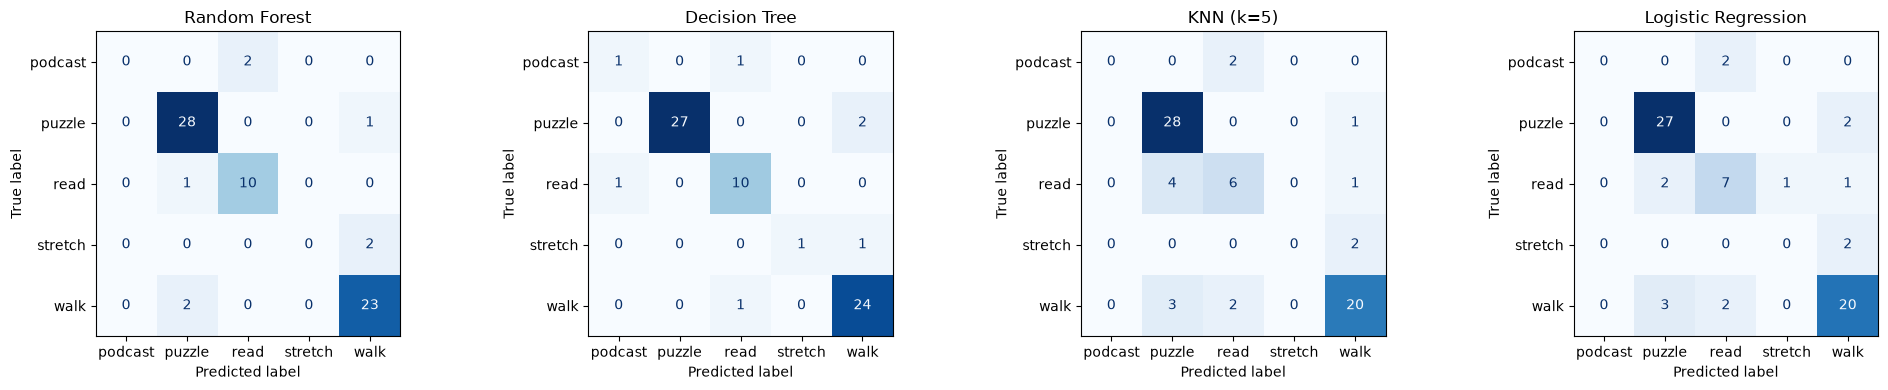

In [ ]:
# confusion matrices side by side
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Summary

- All features used are limited to what the Offscroll app can actually track (screen events, app usage, timing) plus optional age/gender from setup
- The app recommends 5 offline activities: walk, puzzle, read, stretch, and podcast — each mapped to different usage patterns
- Random Forest was chosen as the base model and compared against Decision Tree, KNN, and Logistic Regression using 5-fold cross validation
- The target labels were engineered from usage patterns since the dataset predates our app — in production the model would retrain on actual task completion data from Offscroll users
- Random Forest performed best overall; Decision Tree was close but more prone to overfitting on small data